In [1]:

import numpy as np

X_toy = np.array([
    [1, 1],
    [1, 2],
    [2, 1],
    [5, 5],
    [5, 6],
    [6, 5],
    [9, 1],
    [9, 2],
    [10, 1]
])

y_toy = np.array([
    0, 0, 0,
    1, 1, 1,
    2, 2, 2
])

print("X shape:", X_toy.shape)
print("y shape:", y_toy.shape)
print("Classes:", np.unique(y_toy))


X shape: (9, 2)
y shape: (9,)
Classes: [0 1 2]


In [2]:

n = len(y_toy)

weights = np.ones(n) / n

print("Initial sample weights:", weights)
print("Sum of weights:", weights.sum())


Initial sample weights: [0.11111111 0.11111111 0.11111111 0.11111111 0.11111111 0.11111111
 0.11111111 0.11111111 0.11111111]
Sum of weights: 1.0


In [3]:

import numpy as np
from sklearn.tree import DecisionTreeClassifier


weak_learner = DecisionTreeClassifier(
    max_depth=1,
    random_state=42
)

weak_learner.fit(X_toy, y_toy, sample_weight=weights)


predictions = weak_learner.predict(X_toy)


incorrect = (predictions != y_toy)
weighted_error = np.sum(weights * incorrect)

print("True labels:    ", y_toy)
print("Predictions:    ", predictions)
print("Incorrect mask: ", incorrect)
print("Weighted error: ", weighted_error)
print("SAMME threshold:", 2/3)


True labels:     [0 0 0 1 1 1 2 2 2]
Predictions:     [0 0 0 1 1 1 1 1 1]
Incorrect mask:  [False False False False False False  True  True  True]
Weighted error:  0.3333333333333333
SAMME threshold: 0.6666666666666666


In [4]:

K = len(np.unique(y_toy))

alpha = np.log((1 - weighted_error) / weighted_error) + np.log(K - 1)

print("Number of classes:", K)
print("Weighted error:", weighted_error)
print("Alpha:", alpha)


Number of classes: 3
Weighted error: 0.3333333333333333
Alpha: 1.3862943611198908


In [5]:


updated_weights = weights * np.exp(alpha * incorrect)


updated_weights = updated_weights / np.sum(updated_weights)

print("Updated normalized weights:")
print(updated_weights)

print("Sum of weights:", np.sum(updated_weights))


Updated normalized weights:
[0.05555556 0.05555556 0.05555556 0.05555556 0.05555556 0.05555556
 0.22222222 0.22222222 0.22222222]
Sum of weights: 1.0


In [6]:

# Log one complete SAMME round

print("========== SAMME ROUND 1 ==========")

print("\n1. Initial sample weights:")
print(weights)

print("\n2. Weak learner predictions:")
print("True labels: ", y_toy)
print("Predictions: ", predictions)

print("\n3. Weighted error:")
print(weighted_error)

print("\n4. Learner coefficient (alpha):")
print(alpha)

print("\n5. Updated normalized weights:")
print(updated_weights)

print("\nSum of updated weights:", updated_weights.sum())
print("===================================")


========== SAMME ROUND 1 ==========

1. Initial sample weights:
[0.11111111 0.11111111 0.11111111 0.11111111 0.11111111 0.11111111
 0.11111111 0.11111111 0.11111111]

2. Weak learner predictions:
True labels:  [0 0 0 1 1 1 2 2 2]
Predictions:  [0 0 0 1 1 1 1 1 1]

3. Weighted error:
0.3333333333333333

4. Learner coefficient (alpha):
1.3862943611198908

5. Updated normalized weights:
[0.05555556 0.05555556 0.05555556 0.05555556 0.05555556 0.05555556
 0.22222222 0.22222222 0.22222222]

Sum of updated weights: 1.0


In [7]:

import numpy as np
from sklearn.datasets import fetch_olivetti_faces

faces = fetch_olivetti_faces()

X = faces.data
y = faces.target

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Number of classes:", len(np.unique(y)))


downloading Olivetti faces from https://ndownloader.figshare.com/files/5976027 to /root/scikit_learn_data
X shape: (400, 4096)
y shape: (400,)
Number of classes: 40


In [8]:


roll_number = "m26cse008"


seed = int("".join(filter(str.isdigit, roll_number)))

rng = np.random.default_rng(seed)

train_indices = []
val_indices = []
test_indices = []

for identity in np.unique(y):
    indices = np.where(y == identity)[0].copy()
    rng.shuffle(indices)

    train_indices.extend(indices[:6])
    val_indices.extend(indices[6:8])
    test_indices.extend(indices[8:10])

train_indices = np.array(train_indices)
val_indices = np.array(val_indices)
test_indices = np.array(test_indices)


np.savez(
    "olivetti_split.npz",
    train_indices=train_indices,
    val_indices=val_indices,
    test_indices=test_indices,
    seed=seed
)

print("Train:", len(train_indices))
print("Validation:", len(val_indices))
print("Test:", len(test_indices))
print("Split saved successfully.")


Train: 240
Validation: 80
Test: 80
Split saved successfully.


In [9]:
X_train, y_train = X[train_indices], y[train_indices]
X_val, y_val = X[val_indices], y[val_indices]
X_test, y_test = X[test_indices], y[test_indices]

print("Train:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)

Train: (240, 4096) (240,)
Validation: (80, 4096) (80,)
Test: (80, 4096) (80,)


In [10]:

import numpy as np
from sklearn.tree import DecisionTreeClassifier

def samme_train(X_train, y_train, depth, n_rounds):
    n_samples = X_train.shape[0]
    classes = np.unique(y_train)
    K = len(classes)


    sample_weights = np.ones(n_samples) / n_samples

    learners = []
    learner_weights = []
    weighted_errors = []
    max_sample_weights = []
    top10_weight_sums = []

    for t in range(n_rounds):

        stump = DecisionTreeClassifier(
            max_depth=depth,
            random_state=42 + t
        )
        stump.fit(
            X_train, y_train,
            sample_weight=sample_weights
        )


        predictions = stump.predict(X_train)
        incorrect = (predictions != y_train)
        error = np.sum(sample_weights * incorrect)


        if error >= 1 - 1 / K:
            break


        if error <= 0:
            alpha = 10.0
        else:
            alpha = np.log((1 - error) / error) + np.log(K - 1)

        learners.append(stump)
        learner_weights.append(alpha)
        weighted_errors.append(error)


        sample_weights *= np.exp(alpha * incorrect)
        sample_weights /= sample_weights.sum()

        max_sample_weights.append(np.max(sample_weights))
        top10_weight_sums.append(np.sum(np.sort(sample_weights)[-10:]))


        if error <= 0:
            break

    return {
        "classes": classes,
        "learners": learners,
        "learner_weights": np.array(learner_weights),
        "weighted_errors": np.array(weighted_errors),
        "max_sample_weights": np.array(max_sample_weights),
        "top10_weight_sums": np.array(top10_weight_sums)
    }


In [11]:

def samme_predict(model, X):
    classes = model["classes"]
    learners = model["learners"]
    alphas = model["learner_weights"]


    scores = np.zeros((X.shape[0], len(classes)))

    for learner, alpha in zip(learners, alphas):
        predictions = learner.predict(X)

        for j, class_label in enumerate(classes):
            scores[:, j] += alpha * (predictions == class_label)


    return classes[np.argmax(scores, axis=1)]


In [12]:

def samme_accuracy(model, X, y):
    predictions = samme_predict(model, X)
    accuracy = np.mean(predictions == y)
    return accuracy


In [13]:
depths = [1, 2, 3, 4]
rounds = [10, 25, 50, 100]

all_models = {}
results = []

for depth in depths:
    for B in rounds:
        model = samme_train(
            X_train, y_train,
            depth=depth,
            n_rounds=B
        )

        val_predictions = samme_predict(model, X_val)
        val_accuracy = np.mean(val_predictions == y_val)

        all_models[(depth, B)] = model

        results.append({
            "depth": depth,
            "rounds": B,
            "actual_trees": len(model["learners"]),
            "validation_accuracy": val_accuracy
        })

        print(
            f"Depth={depth}, B={B}, "
            f"Trees={len(model['learners'])}, "
            f"Validation accuracy={val_accuracy:.4f}"
        )


Depth=1, B=10, Trees=10, Validation accuracy=0.0375
Depth=1, B=25, Trees=25, Validation accuracy=0.0500
Depth=1, B=50, Trees=50, Validation accuracy=0.1000
Depth=1, B=100, Trees=100, Validation accuracy=0.1375
Depth=2, B=10, Trees=10, Validation accuracy=0.0375
Depth=2, B=25, Trees=25, Validation accuracy=0.1500
Depth=2, B=50, Trees=50, Validation accuracy=0.2000
Depth=2, B=100, Trees=100, Validation accuracy=0.1375
Depth=3, B=10, Trees=10, Validation accuracy=0.1750
Depth=3, B=25, Trees=25, Validation accuracy=0.2250
Depth=3, B=50, Trees=50, Validation accuracy=0.3500
Depth=3, B=100, Trees=100, Validation accuracy=0.4000
Depth=4, B=10, Trees=10, Validation accuracy=0.0875
Depth=4, B=25, Trees=25, Validation accuracy=0.3625
Depth=4, B=50, Trees=50, Validation accuracy=0.4500
Depth=4, B=100, Trees=100, Validation accuracy=0.5125


In [14]:
best_result = max(
    results,
    key=lambda r: r["validation_accuracy"]
)

best_depth = best_result["depth"]
best_B = best_result["rounds"]

best_model = all_models[(best_depth, best_B)]

print("Best depth:", best_depth)
print("Best rounds:", best_B)
print("Best validation accuracy:",
      best_result["validation_accuracy"] * 100, "%")

Best depth: 4
Best rounds: 100
Best validation accuracy: 51.24999999999999 %


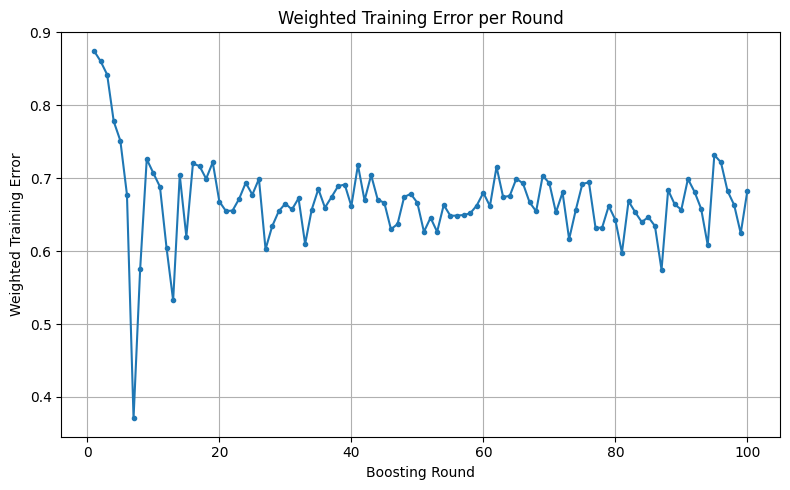

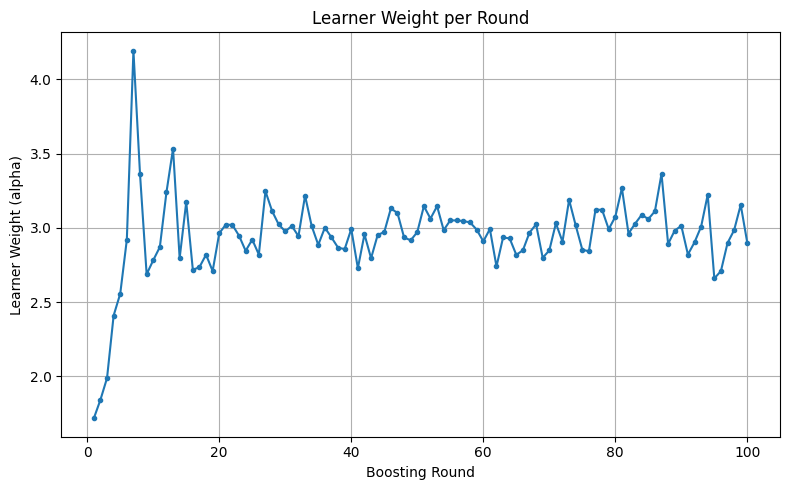

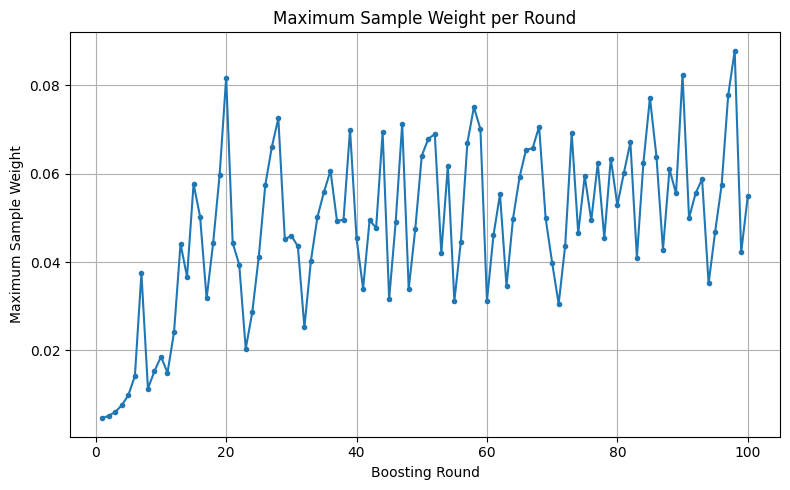

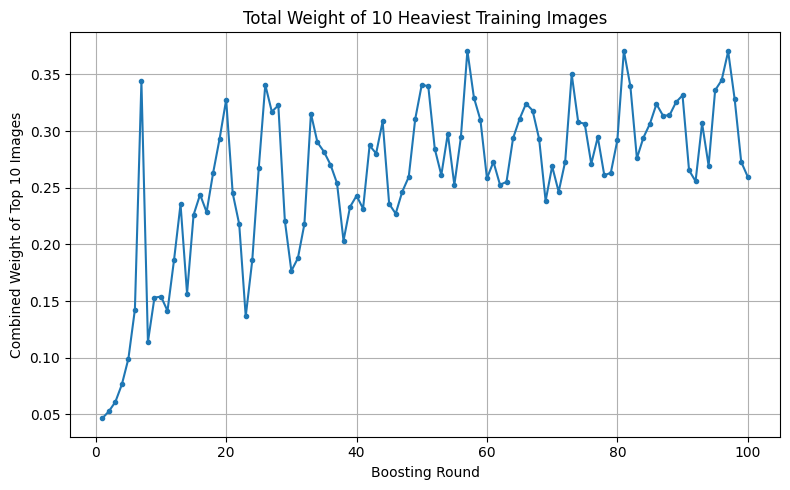

In [15]:

import numpy as np
import matplotlib.pyplot as plt

# Selected best model
best_model = all_models[(best_depth, best_B)]

# Boosting round numbers
T = len(best_model["learners"])
round_numbers = np.arange(1, T + 1)

# Graph 1: Weighted training error
plt.figure(figsize=(8, 5))
plt.plot(round_numbers, best_model["weighted_errors"], marker=".")
plt.xlabel("Boosting Round")
plt.ylabel("Weighted Training Error")
plt.title("Weighted Training Error per Round")
plt.grid(True)
plt.tight_layout()
plt.show()

# Graph 2: Learner weight (alpha)
plt.figure(figsize=(8, 5))
plt.plot(round_numbers, best_model["learner_weights"], marker=".")
plt.xlabel("Boosting Round")
plt.ylabel("Learner Weight (alpha)")
plt.title("Learner Weight per Round")
plt.grid(True)
plt.tight_layout()
plt.show()

# Graph 3: Maximum sample weight
plt.figure(figsize=(8, 5))
plt.plot(round_numbers, best_model["max_sample_weights"], marker=".")
plt.xlabel("Boosting Round")
plt.ylabel("Maximum Sample Weight")
plt.title("Maximum Sample Weight per Round")
plt.grid(True)
plt.tight_layout()
plt.show()

# Graph 4: Total weight of the 10 heaviest training images
plt.figure(figsize=(8, 5))
plt.plot(round_numbers, best_model["top10_weight_sums"], marker=".")
plt.xlabel("Boosting Round")
plt.ylabel("Combined Weight of Top 10 Images")
plt.title("Total Weight of 10 Heaviest Training Images")
plt.grid(True)
plt.tight_layout()
plt.show()



In [16]:
#2)c

In [17]:
import numpy as np
import time
from sklearn.tree import DecisionTreeClassifier

def bagging_train(X_train, y_train, depth, B):
    rng = np.random.default_rng(42)

    models = []
    n = len(X_train)

    start = time.perf_counter()

    for b in range(B):
        # Bootstrap sample: n examples, sampling with replacement
        indices = rng.choice(n, size=n, replace=True)

        X_boot = X_train[indices]
        y_boot = y_train[indices]

        # Train one decision tree
        tree = DecisionTreeClassifier(
            max_depth=depth,
            random_state=42 + b
        )
        tree.fit(X_boot, y_boot)

        models.append(tree)

    training_time = time.perf_counter() - start

    return {
        "models": models,
        "classes": np.unique(y_train),
        "training_time": training_time
    }

In [18]:
def bagging_predict(model, X):
    all_predictions = np.array([
        tree.predict(X)
        for tree in model["models"]
    ])

    predictions = []

    for i in range(X.shape[0]):
        labels, counts = np.unique(
            all_predictions[:, i],
            return_counts=True
        )
        predictions.append(labels[np.argmax(counts)])

    return np.array(predictions)

In [19]:
bagging_models = {}

for B in [25, 50, 100]:
    model = bagging_train(
        X_train, y_train,
        depth=4,
        B=B
    )

    bagging_models[B] = model

    print(
        f"B={B}, "
        f"Training time={model['training_time']:.2f} seconds"
    )

B=25, Training time=8.58 seconds
B=50, Training time=17.66 seconds
B=100, Training time=34.53 seconds


In [20]:
for B in [25, 50, 100]:
    model = bagging_models[B]

    train_acc = np.mean(
        bagging_predict(model, X_train) == y_train
    )
    val_acc = np.mean(
        bagging_predict(model, X_val) == y_val
    )
    test_acc = np.mean(
        bagging_predict(model, X_test) == y_test
    )

    print(f"\nBagging, B={B}")
    print(f"Train accuracy: {train_acc:.4f}")
    print(f"Validation accuracy: {val_acc:.4f}")
    print(f"Clean test accuracy: {test_acc:.4f}")
    print(f"Training time: {model['training_time']:.2f} seconds")


Bagging, B=25
Train accuracy: 0.4208
Validation accuracy: 0.3250
Clean test accuracy: 0.3250
Training time: 8.58 seconds

Bagging, B=50
Train accuracy: 0.5750
Validation accuracy: 0.3750
Clean test accuracy: 0.4125
Training time: 17.66 seconds

Bagging, B=100
Train accuracy: 0.6583
Validation accuracy: 0.4750
Clean test accuracy: 0.4125
Training time: 34.53 seconds


In [21]:
boosting_models = {}

for B in [25, 50, 100]:
    start = time.perf_counter()

    model = samme_train(
        X_train, y_train,
        depth=4,
        n_rounds=B
    )

    training_time = time.perf_counter() - start
    model["training_time"] = training_time

    boosting_models[B] = model

    print(
        f"B={B}, "
        f"Actual learners={len(model['learners'])}, "
        f"Training time={training_time:.2f} seconds"
    )

B=25, Actual learners=25, Training time=10.89 seconds
B=50, Actual learners=50, Training time=21.58 seconds
B=100, Actual learners=100, Training time=45.08 seconds


In [22]:
for B in [25, 50, 100]:
    model = boosting_models[B]

    train_acc = samme_accuracy(model, X_train, y_train)
    val_acc = samme_accuracy(model, X_val, y_val)
    test_acc = samme_accuracy(model, X_test, y_test)

    print(f"\nBoosting, B={B}")
    print(f"Train accuracy: {train_acc:.4f}")
    print(f"Validation accuracy: {val_acc:.4f}")
    print(f"Clean test accuracy: {test_acc:.4f}")
    print(f"Training time: {model['training_time']:.2f} seconds")


Boosting, B=25
Train accuracy: 0.7417
Validation accuracy: 0.3625
Clean test accuracy: 0.2750
Training time: 10.89 seconds

Boosting, B=50
Train accuracy: 0.9708
Validation accuracy: 0.4500
Clean test accuracy: 0.4500
Training time: 21.58 seconds

Boosting, B=100
Train accuracy: 1.0000
Validation accuracy: 0.5125
Clean test accuracy: 0.5375
Training time: 45.08 seconds


In [23]:
def samme_train_with_history(X_train, y_train, depth, n_rounds):
    n_samples = len(X_train)
    classes = np.unique(y_train)
    K = len(classes)

    sample_weights = np.ones(n_samples) / n_samples

    learners = []
    learner_weights = []
    weight_history = []
    prediction_history = []

    for t in range(n_rounds):
        tree = DecisionTreeClassifier(
            max_depth=depth,
            random_state=42 + t
        )

        tree.fit(
            X_train, y_train,
            sample_weight=sample_weights
        )

        predictions = tree.predict(X_train)
        incorrect = predictions != y_train
        error = np.sum(sample_weights * incorrect)

        if error >= 1 - 1 / K:
            break

        alpha = (
            10.0 if error <= 0
            else np.log((1 - error) / error) + np.log(K - 1)
        )

        learners.append(tree)
        learner_weights.append(alpha)

        weight_history.append(sample_weights.copy())
        prediction_history.append(predictions.copy())

        sample_weights *= np.exp(alpha * incorrect)
        sample_weights /= sample_weights.sum()

        if error <= 0:
            break

    return {
        "classes": classes,
        "learners": learners,
        "learner_weights": np.array(learner_weights),
        "weight_history": np.array(weight_history),
        "prediction_history": np.array(prediction_history)
    }

In [24]:
boosting_history_model = samme_train_with_history(
    X_train,
    y_train,
    depth=4,
    n_rounds=100
)

print("Actual boosting rounds:",
      len(boosting_history_model["learners"]))

print("Weight history shape:",
      boosting_history_model["weight_history"].shape)

print("Prediction history shape:",
      boosting_history_model["prediction_history"].shape)

Actual boosting rounds: 100
Weight history shape: (100, 240)
Prediction history shape: (100, 240)


In [25]:
bagging_models = {}

for B in [25, 50, 100]:
    model = bagging_train(
        X_train,
        y_train,
        depth=4,
        B=B
    )

    bagging_models[B] = model

    print(
        f"B={B}, "
        f"Training time={model['training_time']:.2f} seconds"
    )

B=25, Training time=14.79 seconds
B=50, Training time=17.83 seconds
B=100, Training time=36.39 seconds


In [26]:
for B in [25, 50, 100]:
    model = bagging_models[B]

    train_acc = np.mean(
        bagging_predict(model, X_train) == y_train
    )

    val_acc = np.mean(
        bagging_predict(model, X_val) == y_val
    )

    test_acc = np.mean(
        bagging_predict(model, X_test) == y_test
    )

    print(f"\nBagging, B={B}")
    print(f"Train accuracy: {train_acc:.4f}")
    print(f"Validation accuracy: {val_acc:.4f}")
    print(f"Clean test accuracy: {test_acc:.4f}")
    print(f"Training time: {model['training_time']:.2f} seconds")


Bagging, B=25
Train accuracy: 0.4208
Validation accuracy: 0.3250
Clean test accuracy: 0.3250
Training time: 14.79 seconds

Bagging, B=50
Train accuracy: 0.5750
Validation accuracy: 0.3750
Clean test accuracy: 0.4125
Training time: 17.83 seconds

Bagging, B=100
Train accuracy: 0.6583
Validation accuracy: 0.4750
Clean test accuracy: 0.4125
Training time: 36.39 seconds


In [27]:
import numpy as np

weight_history = boosting_history_model["weight_history"]

# Find the training image with the highest weight
sample_idx = np.argmax(weight_history[-1])

print("Training image index:", sample_idx)
print("Highest weight:", weight_history[-1, sample_idx])
print("True identity:", y_train[sample_idx])

Training image index: 210
Highest weight: 0.0422238168076585
True identity: 35


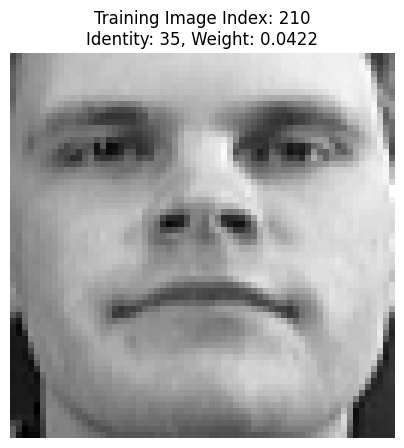

In [28]:
import matplotlib.pyplot as plt
import numpy as np

weight_history = boosting_history_model["weight_history"]
sample_idx = np.argmax(weight_history[-1])

plt.figure(figsize=(5, 5))
plt.imshow(X_train[sample_idx].reshape(64, 64), cmap="gray")
plt.title(
    f"Training Image Index: {sample_idx}\n"
    f"Identity: {y_train[sample_idx]}, "
    f"Weight: {weight_history[-1, sample_idx]:.4f}"
)
plt.axis("off")
plt.show()

In [29]:
import numpy as np
from sklearn.tree import DecisionTreeClassifier

# 1. Freeze the already-trained selected Boosting model
# No retraining of Boosting
selected_boosting_model = boosting_models[100]

# 2. Create masked test set: zero the central 16x16 region
X_test_masked = X_test.reshape(-1, 64, 64).copy()
X_test_masked[:, 24:40, 24:40] = 0
X_test_masked = X_test_masked.reshape(-1, 4096)

# 3. Train the selected single-tree baseline
single_tree_model = DecisionTreeClassifier(
    max_depth=None,
    min_samples_leaf=4,
    random_state=42
)
single_tree_model.fit(X_train, y_train)

# 4. Train the final 200-tree Bagging model
# Using the selected base-tree configuration
final_bagging_model = bagging_train(
    X_train, y_train,
    depth=None,
    B=200
)

print("Boosting model frozen: depth=4, B=100")
print("Single-tree baseline ready.")
print("Final Bagging model ready: B=200.")
print("Clean test shape:", X_test.shape)
print("Masked test shape:", X_test_masked.shape)

Boosting model frozen: depth=4, B=100
Single-tree baseline ready.
Final Bagging model ready: B=200.
Clean test shape: (80, 4096)
Masked test shape: (80, 4096)


In [30]:
import numpy as np

def evaluate_model(name, model, X, y):
    # Get class predictions and probabilities
    if name == "Boosting":
        # Use your existing SAMME prediction function
        predictions = samme_predict(model, X)
        # If your SAMME function returns weighted vote shares,
        # we will use those in the next step.
    else:
        predictions = (
            bagging_predict(model, X)
            if name == "Bagging"
            else model.predict(X)
        )

    accuracy = np.mean(predictions == y)
    print(f"{name} accuracy: {accuracy:.4f}")
    return predictions


print("CLEAN TEST SET")
tree_clean = evaluate_model(
    "Single Tree", single_tree_model, X_test, y_test
)
bag_clean = evaluate_model(
    "Bagging", final_bagging_model, X_test, y_test
)
boost_clean = evaluate_model(
    "Boosting", selected_boosting_model, X_test, y_test
)

print("\nMASKED TEST SET")
tree_masked = evaluate_model(
    "Single Tree", single_tree_model, X_test_masked, y_test
)
bag_masked = evaluate_model(
    "Bagging", final_bagging_model, X_test_masked, y_test
)
boost_masked = evaluate_model(
    "Boosting", selected_boosting_model, X_test_masked, y_test
)

CLEAN TEST SET
Single Tree accuracy: 0.4875
Bagging accuracy: 0.9250
Boosting accuracy: 0.5375

MASKED TEST SET
Single Tree accuracy: 0.4875
Bagging accuracy: 0.8500
Boosting accuracy: 0.4125


In [31]:
print("Bagging model type:", type(final_bagging_model))
print("Bagging model keys:",
      final_bagging_model.keys()
      if isinstance(final_bagging_model, dict)
      else "Not a dictionary")

print("Boosting model type:", type(selected_boosting_model))
print("Boosting model keys:",
      selected_boosting_model.keys()
      if isinstance(selected_boosting_model, dict)
      else "Not a dictionary")

Bagging model type: <class 'dict'>
Bagging model keys: dict_keys(['models', 'classes', 'training_time'])
Boosting model type: <class 'dict'>
Boosting model keys: dict_keys(['classes', 'learners', 'learner_weights', 'weighted_errors', 'max_sample_weights', 'top10_weight_sums', 'training_time'])


In [32]:
import numpy as np

def bagging_vote_shares(model, X):
    classes = model["classes"]
    votes = np.zeros((len(X), len(classes)))

    for tree in model["models"]:
        pred = tree.predict(X)
        for i, cls in enumerate(classes):
            votes[:, i] += (pred == cls)

    votes /= len(model["models"])
    return votes


def boosting_vote_shares(model, X):
    classes = model["classes"]
    scores = np.zeros((len(X), len(classes)))

    for learner, alpha in zip(
        model["learners"], model["learner_weights"]
    ):
        pred = learner.predict(X)
        for i, cls in enumerate(classes):
            scores[:, i] += alpha * (pred == cls)

    scores /= np.sum(model["learner_weights"])
    return scores


def report_winning_share(name, shares):
    winning_share = np.max(shares, axis=1).mean()
    print(f"{name} mean winning vote/probability: {winning_share:.4f}")


# Single tree: predicted class probability
for split_name, X in [
    ("Clean", X_test),
    ("Masked", X_test_masked)
]:
    tree_probs = single_tree_model.predict_proba(X)
    report_winning_share(f"Single Tree ({split_name})", tree_probs)

    bag_shares = bagging_vote_shares(final_bagging_model, X)
    report_winning_share(f"Bagging ({split_name})", bag_shares)

    boost_shares = boosting_vote_shares(selected_boosting_model, X)
    report_winning_share(f"Boosting ({split_name})", boost_shares)

Single Tree (Clean) mean winning vote/probability: 0.9857
Bagging (Clean) mean winning vote/probability: 0.3894
Boosting (Clean) mean winning vote/probability: 0.1123
Single Tree (Masked) mean winning vote/probability: 0.9857
Bagging (Masked) mean winning vote/probability: 0.2726
Boosting (Masked) mean winning vote/probability: 0.1157


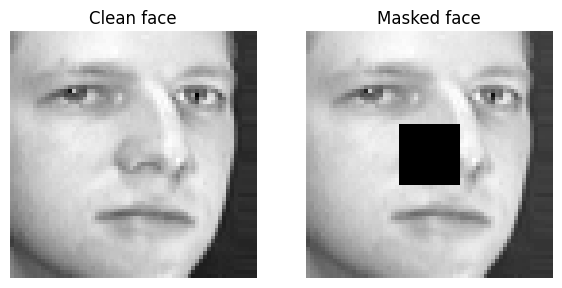

Test-set index: 1
True identity: 0
Bagging: clean=0, masked=1
Boosting: clean=4, masked=4
Bagging vote share, clean/masked: 0.205 0.155
Boosting weighted share, clean/masked: 0.1101 0.1302


In [33]:
import numpy as np
import matplotlib.pyplot as plt

classes = np.asarray(final_bagging_model["classes"])

# Class vote shares on clean and masked images
bag_clean_shares = bagging_vote_shares(final_bagging_model, X_test)
bag_masked_shares = bagging_vote_shares(final_bagging_model, X_test_masked)

boost_clean_shares = boosting_vote_shares(selected_boosting_model, X_test)
boost_masked_shares = boosting_vote_shares(selected_boosting_model, X_test_masked)

bag_clean_pred = classes[np.argmax(bag_clean_shares, axis=1)]
bag_masked_pred = classes[np.argmax(bag_masked_shares, axis=1)]

boost_clean_pred = classes[np.argmax(boost_clean_shares, axis=1)]
boost_masked_pred = classes[np.argmax(boost_masked_shares, axis=1)]

# Prefer a face where one model changes its prediction and the other doesn't
bag_changed = bag_clean_pred != bag_masked_pred
boost_changed = boost_clean_pred != boost_masked_pred

candidates = np.where(bag_changed != boost_changed)[0]

# If none, use a face where their clean-to-masked changes differ
if len(candidates) == 0:
    candidates = np.where(
        (bag_clean_pred != boost_clean_pred) |
        (bag_masked_pred != boost_masked_pred)
    )[0]

if len(candidates) == 0:
    print("No face with different prediction behaviour found.")
else:
    idx = candidates[0]

    fig, axes = plt.subplots(1, 2, figsize=(7, 4))
    axes[0].imshow(X_test[idx].reshape(64, 64), cmap="gray")
    axes[0].set_title("Clean face")
    axes[0].axis("off")

    axes[1].imshow(X_test_masked[idx].reshape(64, 64), cmap="gray")
    axes[1].set_title("Masked face")
    axes[1].axis("off")
    plt.show()

    print("Test-set index:", idx)
    print("True identity:", y_test[idx])
    print(f"Bagging: clean={bag_clean_pred[idx]}, masked={bag_masked_pred[idx]}")
    print(f"Boosting: clean={boost_clean_pred[idx]}, masked={boost_masked_pred[idx]}")
    print("Bagging vote share, clean/masked:",
          round(bag_clean_shares[idx].max(), 4),
          round(bag_masked_shares[idx].max(), 4))
    print("Boosting weighted share, clean/masked:",
          round(boost_clean_shares[idx].max(), 4),
          round(boost_masked_shares[idx].max(), 4))